# 1. Exploratory data analysis

**Project question:** which lifestyle and health factors are associated with heart disease among BRFSS 2021 respondents, and how well can heart disease be predicted from them?

This notebook gets to know the data before any testing or modelling:

1. what is in the file and what the variables mean,
2. whether the values are plausible, and what to do with the ones that are not,
3. how common heart disease is, overall and across groups,
4. how each variable relates to heart disease.

All cleaning and plotting logic lives in `src/cvd/`; the notebook only calls it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter

from cvd import SEED, data, plots, stats
from cvd.data import LABELS, TARGET

plots.set_style()
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.width", 160)

## 1.1 Loading and cleaning

The raw file is the Kaggle CSV exactly as distributed. `data.clean` drops exact duplicate rows, renames the columns to snake_case, turns the target into 0/1 and gives every categorical variable a fixed set of levels (ordered where there is a natural order).

In [2]:
raw = data.load_raw()
df = data.clean(raw)

print(f"Raw file:       {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"Missing values: {int(raw.isna().sum().sum())}")
print(f"Exact duplicate rows dropped: {len(raw) - len(df)}")
print(f"Cleaned data:   {df.shape[0]:,} rows x {df.shape[1]} columns")

Raw file:       308,854 rows x 19 columns
Missing values: 0
Exact duplicate rows dropped: 80
Cleaned data:   308,774 rows x 19 columns


There are no missing values. BRFSS itself has many refused and skipped answers, so incomplete responses were evidently removed when the Kaggle file was prepared. That is convenient, but it means the file is a complete-case subset of BRFSS and we cannot check who was removed.

The 80 duplicates are dropped as a judgment call. The file has no respondent ID, so two people with identical answers are indistinguishable from one person entered twice. At 0.03% of rows it does not affect any result.

In [3]:
overview = pd.DataFrame(
    {
        "label": [LABELS[c] for c in df.columns],
        "dtype": [
            "ordered categorical"
            if isinstance(df[c].dtype, pd.CategoricalDtype) and df[c].cat.ordered
            else str(df[c].dtype)
            for c in df.columns
        ],
        "distinct": df.nunique(),
        "values": [
            ", ".join(map(str, df[c].cat.categories[:5])) + (" ..." if df[c].nunique() > 5 else "")
            if isinstance(df[c].dtype, pd.CategoricalDtype)
            else f"{df[c].min():g} to {df[c].max():g}"
            for c in df.columns
        ],
    }
)
overview

,label,dtype,distinct,values
general_health,Self-rated general health,ordered categorical,5,"Poor, Fair, Good, Very Good, Excellent"
checkup,Last routine checkup,ordered categorical,5,"Never, 5 or more years ago, Within the past 5 ..."
exercise,Exercise in past 30 days,category,2,"No, Yes"
heart_disease,Heart disease,int8,2,0 to 1
skin_cancer,Skin cancer,category,2,"No, Yes"
other_cancer,Other cancer,category,2,"No, Yes"
depression,Depression,category,2,"No, Yes"
diabetes,Diabetes,category,4,"No, Pre-diabetes, Gestational only, Yes"
arthritis,Arthritis,category,2,"No, Yes"
sex,Sex,category,2,"Female, Male"


The data has one binary target (`heart_disease`), eleven categorical predictors and seven numeric ones. Three of the categoricals are ordinal (general health, time since last checkup, age group) and are stored with their order so plots and models treat them correctly.

## 1.2 What the variables mean

The full column dictionary is in [`data/README.md`](../data/README.md). The Kaggle page does not document units, so two things had to be inferred:

- **Fruit, green vegetables, fried potatoes:** assumed to be *times eaten per month*. BRFSS 2021 asks "how often did you eat ..." and lets people answer per day, per week or per month.
- **Alcohol:** assumed to be *days with at least one drink in the past 30 days*.

If these assumptions are right, the data should show it: answers given "per day" or "per week" get multiplied up, so values should pile up at multiples of 30 and of 4, and alcohol should never exceed 30.

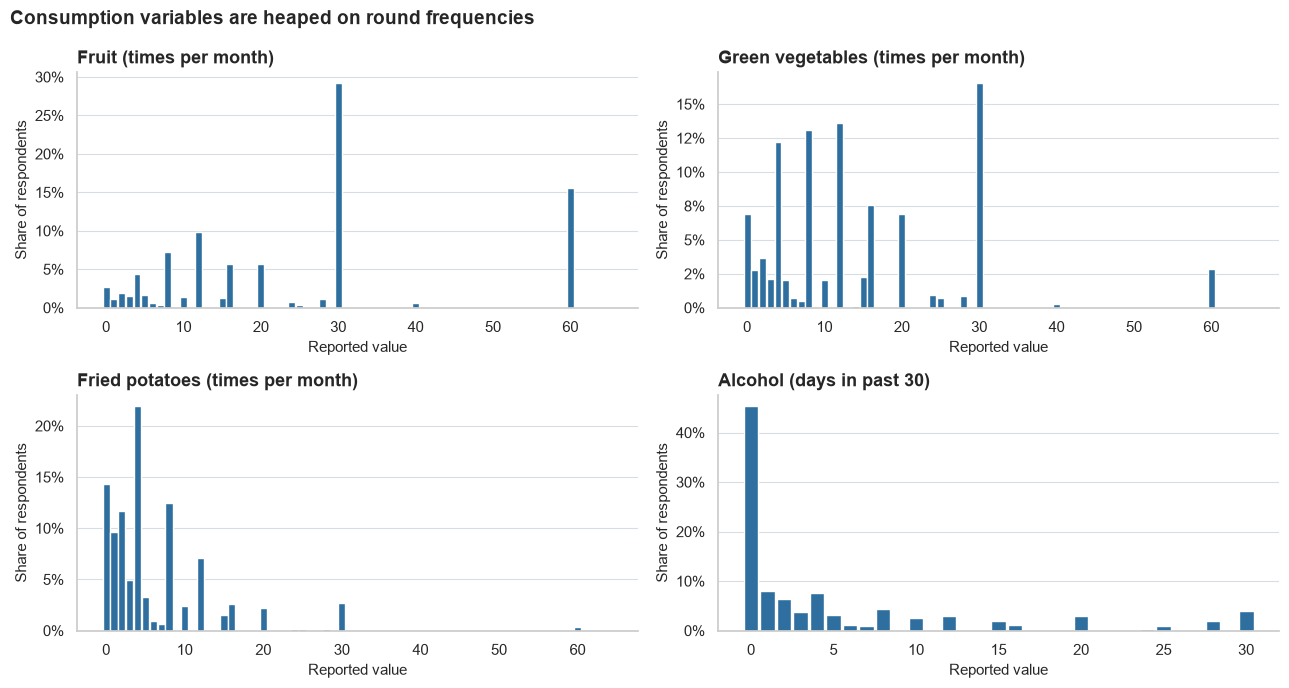

,max,share at exactly 30,share at exactly 60,share at multiples of 4,share at zero
alcohol_consumption,30.000,0.039,0.000,0.667,0.454
fruit_consumption,120.000,0.292,0.156,0.548,0.027
green_vegetables_consumption,128.000,0.166,0.028,0.655,0.069
fried_potato_consumption,128.000,0.027,0.004,0.615,0.143


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, col in zip(
    axes.ravel(),
    ["fruit_consumption", "green_vegetables_consumption", "fried_potato_consumption", "alcohol_consumption"],
    strict=True,
):
    plots.discrete_distribution(df[col], ax, LABELS[col], "Reported value", max_value=65)
fig.suptitle("Consumption variables are heaped on round frequencies", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

heaping = pd.DataFrame(
    {
        "max": df[data.NUMERIC_COLS[3:]].max(),
        "share at exactly 30": (df[data.NUMERIC_COLS[3:]] == 30).mean(),
        "share at exactly 60": (df[data.NUMERIC_COLS[3:]] == 60).mean(),
        "share at multiples of 4": (df[data.NUMERIC_COLS[3:]] % 4 == 0).mean(),
        "share at zero": (df[data.NUMERIC_COLS[3:]] == 0).mean(),
    }
)
heaping

**Takeaway.** The pattern supports the assumed units. Fruit spikes at 30 and 60 (once and twice a day; 29% and 16% of respondents), the food variables cluster on multiples of 4 (weekly answers × 4), and alcohol stops at exactly 30. These are therefore coarse, self-reported frequencies rather than measurements, and are best read as "roughly how often".

## 1.3 Sanity checks on height, weight and BMI

Body measurements are self-reported and were converted from feet/inches and pounds by BRFSS, so some odd values are expected.

In [5]:
df[["height_cm", "weight_kg", "bmi"]].describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).T

,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
height_cm,"308,774.000",170.615,10.658,91.000,137.000,150.000,170.000,193.000,203.000,241.000
weight_kg,"308,774.000",83.590,21.345,24.950,40.370,47.630,81.650,147.420,190.510,293.020
bmi,"308,774.000",28.627,6.523,12.020,15.338,18.010,27.440,49.493,64.020,99.330


The middle 99.8% of each variable is unremarkable, but the extremes are not: heights of 91 cm and 241 cm, weights of 25 kg and 293 kg, and BMI up to 99. First, is `bmi` simply weight / height², or an independent measurement?

In [6]:
flagged = data.add_quality_flags(df)
bmi_gap = (flagged["bmi"] - flagged["bmi_recomputed"]).abs()
print(f"Median |reported BMI - recomputed BMI|: {bmi_gap.median():.3f}")
print(f"99.9th percentile of the gap:           {bmi_gap.quantile(0.999):.3f}")
print(f"Largest gap:                            {bmi_gap.max():.3f}")
print(f"Rows where the gap exceeds 0.5:         {int(flagged['flag_bmi_mismatch'].sum()):,}")

Median |reported BMI - recomputed BMI|: 0.079
99.9th percentile of the gap:           0.317
Largest gap:                            0.988
Rows where the gap exceeds 0.5:         13


**Takeaway.** Reported BMI is weight / height² up to rounding: the typical gap is under 0.1, and only 13 rows differ by more than 0.5 (height is stored in whole centimetres, which accounts for small gaps). BMI therefore carries no information beyond height and weight, and all three should never enter a linear model together. From here on the models use BMI only (height is mostly a proxy for sex, as notebook 2 shows).

### Outlier policy

Values are **flagged, not dropped**. A row is flagged as implausible if any of these holds:

| Variable | Plausible range used | Why |
|---|---|---|
| Height | 120–220 cm | Outside this range adult heights are extremely rare; more likely a conversion or entry error |
| Weight | 30–250 kg | Same reasoning |
| BMI | 12–70 kg/m² | Values beyond this are barely compatible with a person answering a phone survey |

The limits are deliberately generous: the aim is to catch likely errors, not to trim legitimate heavy or light people.

                    rows  heart_disease_prevalence  share_of_rows
flag_implausible                                                 
False             308540                     0.081          0.999
True                 234                     0.064          0.001


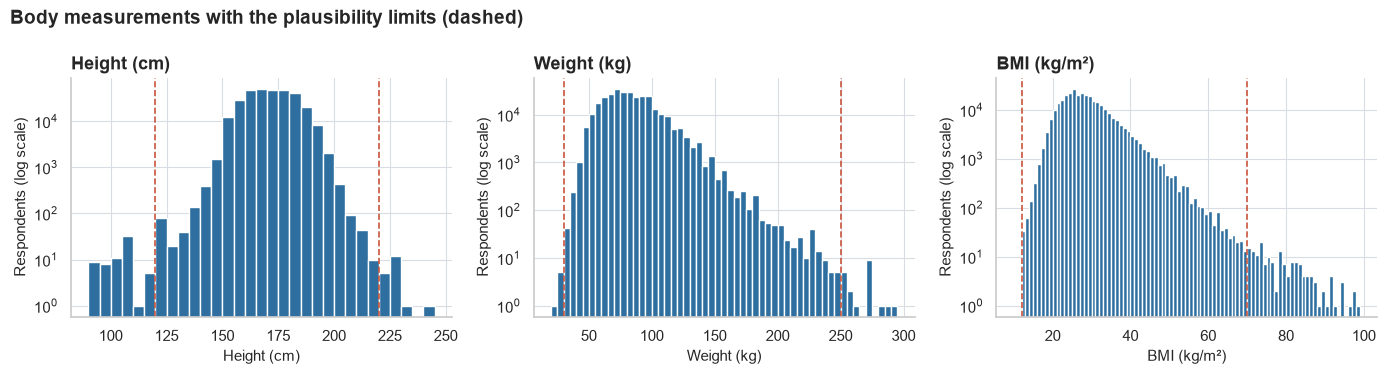

In [7]:
flag_summary = flagged.groupby("flag_implausible")[TARGET].agg(rows="size", heart_disease_prevalence="mean")
flag_summary["share_of_rows"] = flag_summary["rows"] / len(flagged)
print(flag_summary)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, bins in zip(
    axes,
    ["height_cm", "weight_kg", "bmi"],
    [np.arange(90, 246, 5), np.arange(20, 300, 5), np.arange(10, 100, 1)],
    strict=True,
):
    ax.hist(df[col], bins=bins, color=plots.BLUE)
    for limit in data.PLAUSIBLE_RANGES[col]:
        ax.axvline(limit, color=plots.RED, linestyle="--", linewidth=1.2)
    ax.set_yscale("log")
    ax.set_xlabel(LABELS[col])
    ax.set_ylabel("Respondents (log scale)")
    ax.set_title(LABELS[col])
fig.suptitle("Body measurements with the plausibility limits (dashed)", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

**Takeaway.** Only 234 rows (0.08%) fall outside the limits; the log scale is needed to see them at all. Their heart disease prevalence (6.4%) is close to everyone else's (8.1%), so they are not a special risk group. They are kept in the data: tree-based models are insensitive to extreme inputs, and notebook 3 refits the logistic regression without the flagged rows to confirm that they do not drive the estimates.

## 1.4 How common is heart disease?

In [8]:
events, n = int(df[TARGET].sum()), len(df)
low, high = stats.wilson_ci(events, n)
print(f"Heart disease: {events:,} of {n:,} respondents = {events / n:.2%} (95% CI {low:.2%} to {high:.2%})")
print(f"Ratio of negatives to positives: {(n - events) / events:.1f} to 1")

Heart disease: 24,971 of 308,774 respondents = 8.09% (95% CI 7.99% to 8.18%)
Ratio of negatives to positives: 11.4 to 1


About one respondent in twelve reports heart disease. This imbalance shapes the modelling: a model that says "no" to everyone is right 92% of the time, so accuracy is a useless metric here, and notebook 4 uses precision-recall based metrics.

This is the prevalence **in this file**. BRFSS is a weighted survey and the file has no weights, so it is not an estimate for the US population.

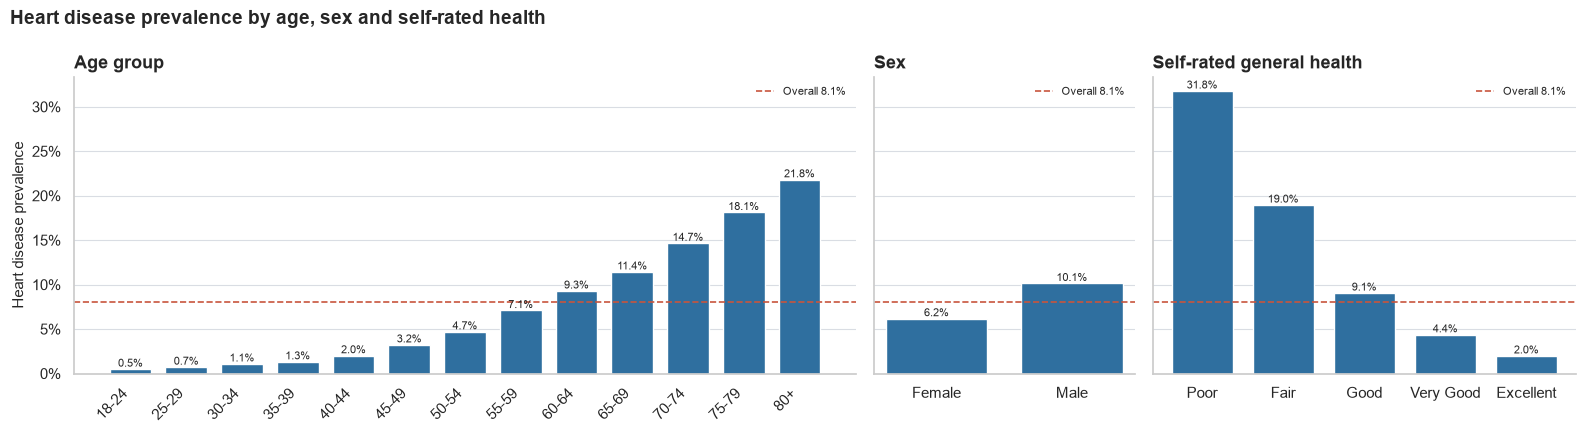

age_category      18-24      25-29      30-34      35-39      40-44      45-49      50-54      55-59      60-64      65-69      70-74      75-79        80+
n            18,670.000 15,492.000 18,425.000 20,598.000 21,587.000 20,963.000 25,090.000 28,048.000 32,409.000 33,425.000 31,099.000 20,699.000 22,269.000
prevalence        0.005      0.007      0.011      0.013      0.020      0.032      0.047      0.071      0.093      0.114      0.147      0.181      0.218 

sex             Female        Male
n          160,155.000 148,619.000
prevalence       0.062       0.101 

general_health       Poor       Fair       Good   Very Good  Excellent
n              11,331.000 35,808.000 95,355.000 110,351.000 55,929.000
prevalence          0.318      0.190      0.091       0.044      0.020 



In [9]:
base_rate = df[TARGET].mean()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [2.4, 0.8, 1.3]}, sharey=True)
for ax, col in zip(axes, ["age_category", "sex", "general_health"], strict=True):
    table = df.groupby(col, observed=True)[TARGET].agg(prevalence="mean")
    plots.prevalence_bar(
        table, ax, LABELS[col], "", base_rate=base_rate, rotate=45 if col == "age_category" else 0, ylabel=col == "age_category"
    )
fig.suptitle("Heart disease prevalence by age, sex and self-rated health", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
plots.save_figure(fig, "prevalence_by_age_sex_health")
plt.show()

for col in ["age_category", "sex", "general_health"]:
    print(df.groupby(col, observed=True)[TARGET].agg(n="size", prevalence="mean").T.round(3), "\n")

**Takeaway.** Age dominates everything else: prevalence climbs steadily from under 1% in the youngest group to over 20% in the oldest. Men report heart disease more often than women, and prevalence rises steeply as self-rated health worsens. Any comparison between groups that differ in age will largely reflect that age difference, which is why later notebooks adjust for age.

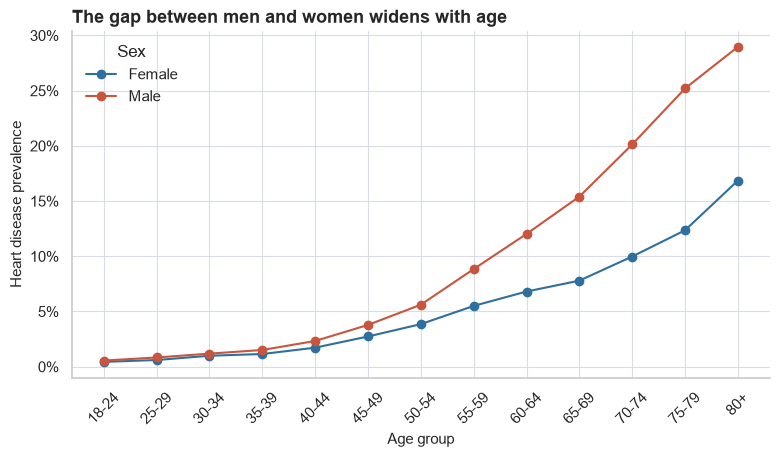

age_category
18-24   1.260
25-29   1.380
30-34   1.190
35-39   1.320
40-44   1.350
45-49   1.380
50-54   1.460
55-59   1.610
60-64   1.770
65-69   1.980
70-74   2.020
75-79   2.040
80+     1.720


In [10]:
age_sex = df.groupby(["age_category", "sex"], observed=True)[TARGET].mean().unstack()
fig, ax = plt.subplots(figsize=(9, 4.5))
for sex, color in [("Female", plots.BLUE), ("Male", plots.RED)]:
    ax.plot(age_sex.index.astype(str), age_sex[sex], marker="o", color=color, label=sex)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Age group")
ax.set_ylabel("Heart disease prevalence")
ax.set_title("The gap between men and women widens with age")
ax.tick_params(axis="x", rotation=45)
ax.legend(title="Sex")
plt.show()
print((age_sex["Male"] / age_sex["Female"]).rename("male / female prevalence ratio").round(2).to_string())

**Takeaway.** Men have higher prevalence than women in every age group. The ratio grows from about 1.3 before age 50 to about 2 at ages 65-79, so the absolute gap widens sharply with age. Sex and age are both needed in any model.

## 1.5 Categorical variables against heart disease

The same view for the remaining categorical variables. The dashed line is the overall prevalence, so a bar above it marks a group with more heart disease than average.

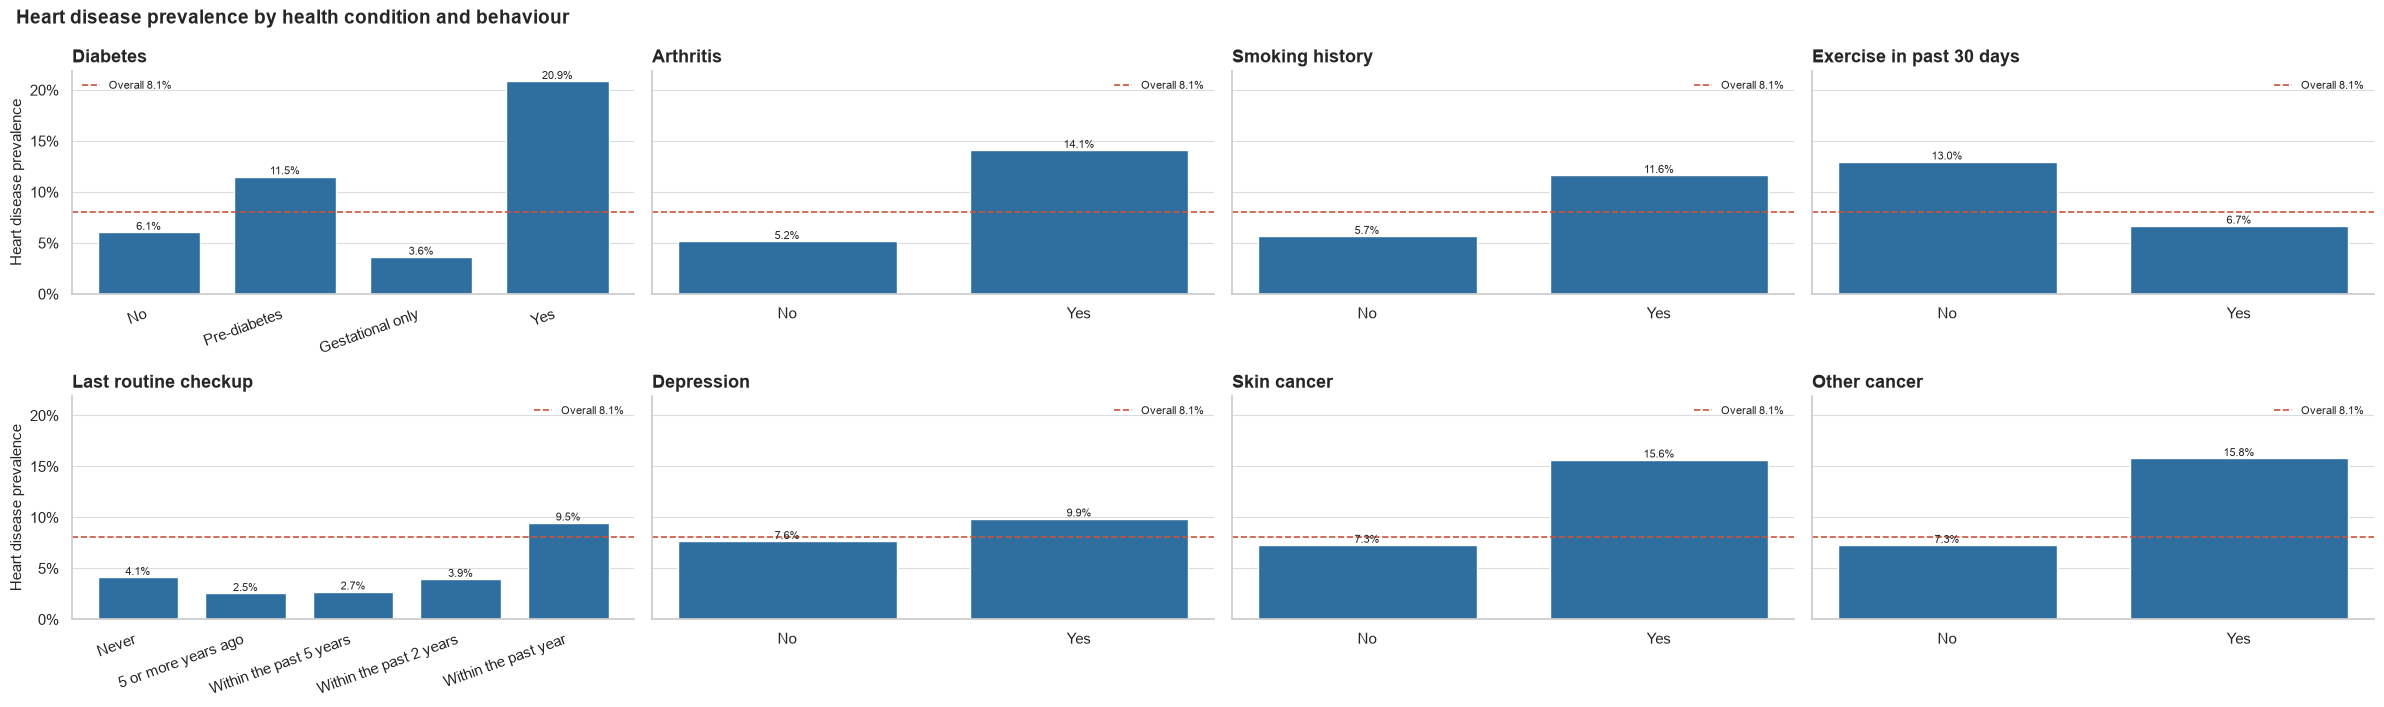

,lowest,highest,smallest group n
variable,,,
diabetes,Gestational only (3.6%),Yes (20.9%),2646
arthritis,No (5.2%),Yes (14.1%),101063
smoking_history,No (5.7%),Yes (11.6%),125258
exercise,Yes (6.7%),No (13.0%),69469
checkup,5 or more years ago (2.5%),Within the past year (9.5%),1407
depression,No (7.6%),Yes (9.9%),61899
skin_cancer,No (7.3%),Yes (15.6%),29992
other_cancer,No (7.3%),Yes (15.8%),29877


In [11]:
fig = plots.prevalence_grid(
    df,
    ["diabetes", "arthritis", "smoking_history", "exercise", "checkup", "depression", "skin_cancer", "other_cancer"],
    TARGET,
    LABELS,
    ncols=4,
    suptitle="Heart disease prevalence by health condition and behaviour",
)
plt.show()

rows = []
for col in ["diabetes", "arthritis", "smoking_history", "exercise", "checkup", "depression", "skin_cancer", "other_cancer"]:
    table = df.groupby(col, observed=True)[TARGET].agg(n="size", prevalence="mean")
    rows.append(
        {
            "variable": col,
            "lowest": f"{table['prevalence'].idxmin()} ({table['prevalence'].min():.1%})",
            "highest": f"{table['prevalence'].idxmax()} ({table['prevalence'].max():.1%})",
            "smallest group n": int(table["n"].min()),
        }
    )
pd.DataFrame(rows).set_index("variable")

**Takeaway.** Every condition goes with more heart disease, most strongly diabetes and arthritis. Smokers and people who do not exercise also have higher prevalence. Two patterns need care:

- **Checkup:** people who saw a doctor within the past year have the *highest* prevalence. Doctor visits do not cause heart disease; people with heart disease see doctors more. This is reverse causation, and it returns in notebook 3.
- **All of these groups are also older.** Diabetes, arthritis and cancer are diseases of age, so part of each gap is an age gap. The raw differences here are a description, not an explanation.

## 1.6 Numeric variables against heart disease

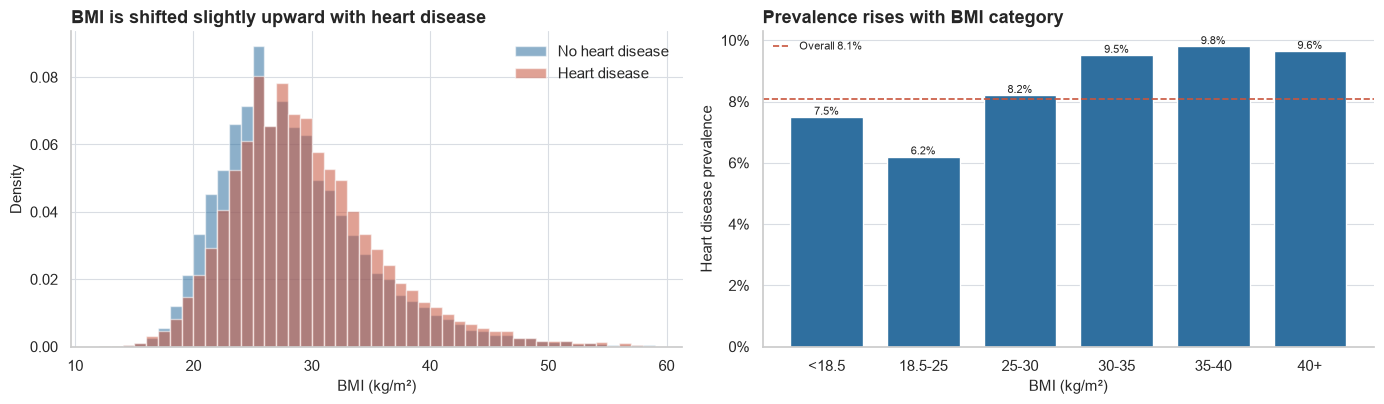

              n  prevalence
bmi                        
<18.5      4537       0.075
18.5-25   89723       0.062
25-30    109676       0.082
30-35     61223       0.095
35-40     25924       0.098
40+       17691       0.096


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
plots.histogram_by_target(df, "bmi", TARGET, axes[0], "BMI is shifted slightly upward with heart disease", LABELS["bmi"], np.arange(12, 60, 1))
bmi_table = stats.binned_prevalence(
    df, "bmi", TARGET, [0, 18.5, 25, 30, 35, 40, 200], ["<18.5", "18.5-25", "25-30", "30-35", "35-40", "40+"]
)
plots.prevalence_bar(bmi_table, axes[1], "Prevalence rises with BMI category", LABELS["bmi"], base_rate=base_rate)
fig.tight_layout()
plt.show()
print(bmi_table.round(3))

**Takeaway.** The two BMI distributions overlap almost completely; the heart disease group sits only slightly higher. Prevalence rises from 6.2% at normal weight to about 9.5% at BMI 30-35 and then levels off; that is far less than the spread across age groups. Underweight respondents have *higher* prevalence (7.5%) than normal-weight ones, which hints at illness-related weight loss rather than any benefit of being light.

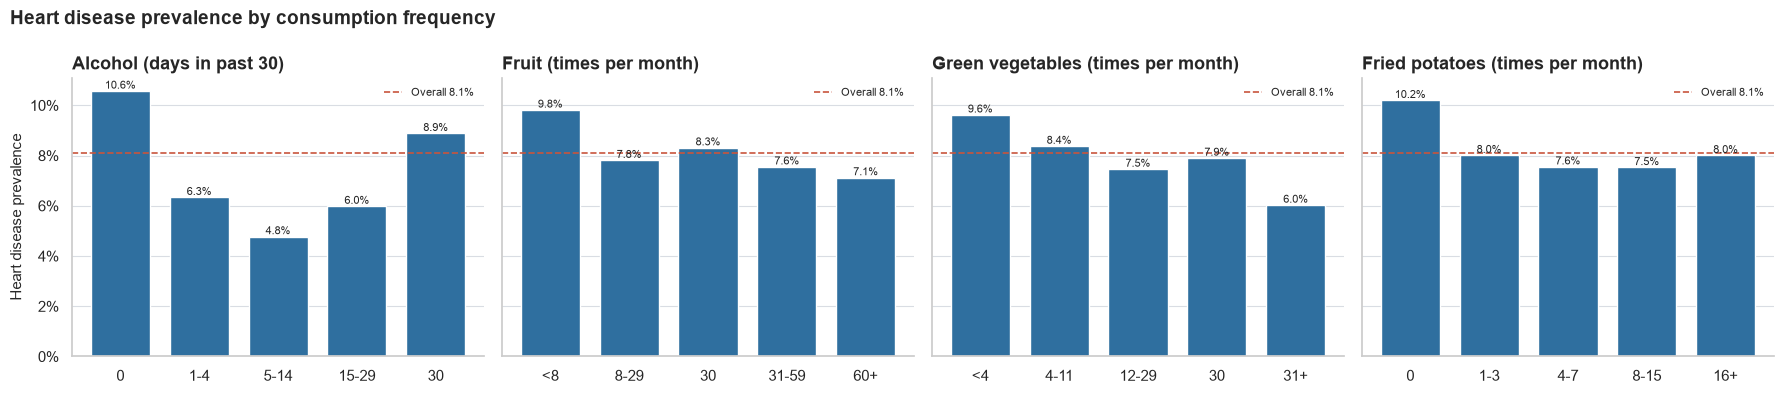

alcohol_consumption {'0': 0.106, '1-4': 0.063, '5-14': 0.048, '15-29': 0.06, '30': 0.089}
fruit_consumption {'<8': 0.098, '8-29': 0.078, '30': 0.083, '31-59': 0.076, '60+': 0.071}
green_vegetables_consumption {'<4': 0.096, '4-11': 0.084, '12-29': 0.075, '30': 0.079, '31+': 0.06}
fried_potato_consumption {'0': 0.102, '1-3': 0.08, '4-7': 0.076, '8-15': 0.075, '16+': 0.08}


In [13]:
bin_specs = {
    "alcohol_consumption": ([0, 1, 5, 15, 30, 31], ["0", "1-4", "5-14", "15-29", "30"]),
    "fruit_consumption": ([0, 8, 30, 31, 60, 200], ["<8", "8-29", "30", "31-59", "60+"]),
    "green_vegetables_consumption": ([0, 4, 12, 30, 31, 200], ["<4", "4-11", "12-29", "30", "31+"]),
    "fried_potato_consumption": ([0, 1, 4, 8, 16, 200], ["0", "1-3", "4-7", "8-15", "16+"]),
}
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
binned_tables = {}
for ax, (col, (bins, names)) in zip(axes, bin_specs.items(), strict=True):
    binned_tables[col] = stats.binned_prevalence(df, col, TARGET, bins, names)
    plots.prevalence_bar(binned_tables[col], ax, LABELS[col], "", base_rate=base_rate, ylabel=col == "alcohol_consumption")
fig.suptitle("Heart disease prevalence by consumption frequency", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()
for col, table in binned_tables.items():
    print(col, table["prevalence"].round(3).to_dict())

**Takeaway.** The diet variables show weak and partly counter-intuitive raw patterns. The clearest is alcohol: people who do not drink at all have the **highest** prevalence (10.6%), ahead of daily drinkers (8.9%). Likewise, people who never eat fried potatoes have higher prevalence (10.2%) than those who do. Neither is a health tip. Older and sicker people drink less (some stop *because* of a diagnosis), and fried potato consumption is highest among the young. Section 1.7 checks this directly.

## 1.7 How the predictors relate to each other and to age

Spearman rank correlations between the numeric variables, the ordinal variables (as ranks) and the target. This shows which predictors move together, and in particular which ones move with age.

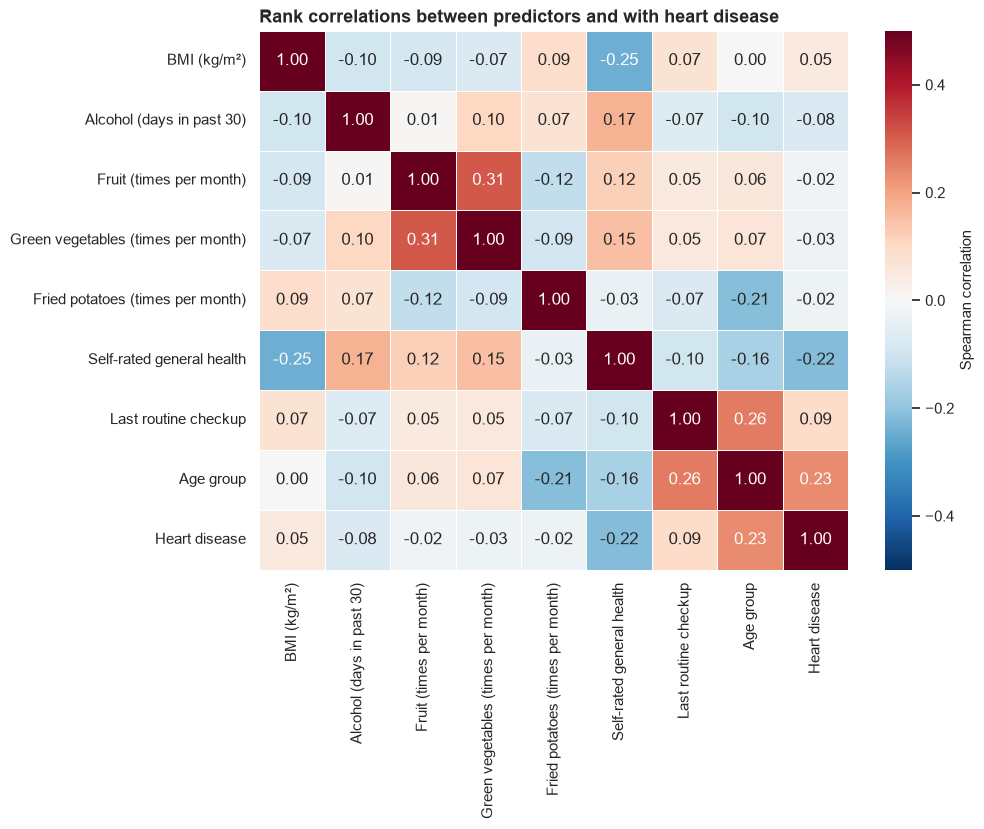

Fried potatoes (times per month)     -0.214
Self-rated general health            -0.162
Alcohol (days in past 30)            -0.097
BMI (kg/m²)                           0.003
Fruit (times per month)               0.058
Green vegetables (times per month)    0.065
Heart disease                         0.235
Last routine checkup                  0.258


In [14]:
corr_data = df[data.NUMERIC_COLS[2:]].copy()
for col in data.ORDERED_LEVELS:
    corr_data[col] = data.ordinal_codes(df[col])
corr_data[TARGET] = df[TARGET]
corr = corr_data.rename(columns=LABELS).corr(method="spearman")

fig, ax = plt.subplots(figsize=(9.5, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.5, vmax=0.5, linewidths=0.5, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title("Rank correlations between predictors and with heart disease")
plt.show()

print(corr[LABELS["age_category"]].drop(LABELS["age_category"]).sort_values().round(3).to_string())

**Takeaway.** No pair of predictors is strongly correlated, so collinearity is not a concern once height and weight are left out. The correlations with age explain the odd diet patterns above: older respondents eat fried potatoes less often and drink on fewer days, and they are also the ones with heart disease. Age is a confounder for almost every lifestyle variable in this data.

## 1.8 A warning about row order

The original exam notebook analysed the first 5,000 rows of the file as if they were a random sample. The check below shows why that is unsafe: if rows were in random order, heart disease prevalence in consecutive blocks of 5,000 rows would vary only by chance.

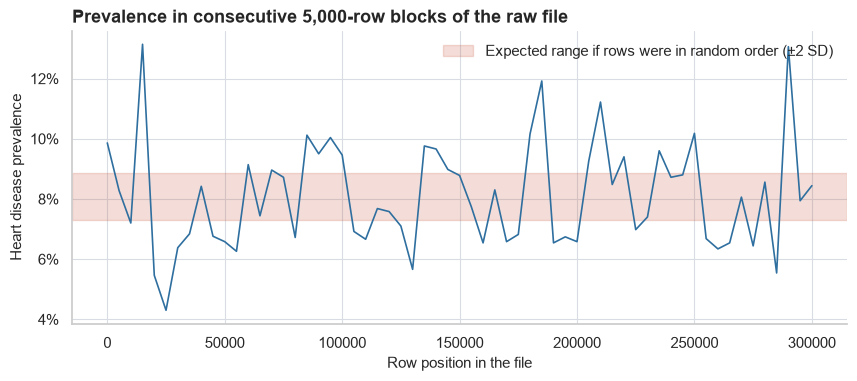

First 5,000 rows: 9.9%   overall: 8.1%
Range across blocks: 4.3% to 13.1%
SD across blocks: 0.0179   expected under random order: 0.0039
Seeded random sample of 5,000 rows: 8.1%


In [15]:
block = np.arange(len(raw)) // 5000
block_rate = (raw["Heart_Disease"] == "Yes").groupby(block).mean().iloc[:-1]
overall = (raw["Heart_Disease"] == "Yes").mean()
expected_sd = np.sqrt(overall * (1 - overall) / 5000)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(block_rate.index * 5000, block_rate, color=plots.BLUE, linewidth=1.2)
ax.axhspan(overall - 2 * expected_sd, overall + 2 * expected_sd, color=plots.RED, alpha=0.2, label="Expected range if rows were in random order (±2 SD)")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Row position in the file")
ax.set_ylabel("Heart disease prevalence")
ax.set_title("Prevalence in consecutive 5,000-row blocks of the raw file")
ax.legend(loc="upper right")
plt.show()

print(f"First 5,000 rows: {block_rate.iloc[0]:.1%}   overall: {overall:.1%}")
print(f"Range across blocks: {block_rate.min():.1%} to {block_rate.max():.1%}")
print(f"SD across blocks: {block_rate.std():.4f}   expected under random order: {expected_sd:.4f}")
rng_sample = raw.sample(5000, random_state=SEED)
print(f"Seeded random sample of 5,000 rows: {(rng_sample['Heart_Disease'] == 'Yes').mean():.1%}")

**Takeaway.** Prevalence swings between blocks several times more than chance allows, so the file is sorted by something related to health (most likely US state, which is not in the file). Any slice taken by position is biased. This project uses the full data throughout, and where a subsample is needed it is drawn at random with a fixed seed.

## Summary

- **Data:** 308,774 respondents after removing 80 exact duplicates, 18 predictors, no missing values. Consumption variables are self-reported frequencies per month, heaped on round numbers.
- **Quality:** BMI is exactly weight / height². A very small share of rows has implausible body measurements; they are flagged and kept.
- **Target:** 8.1% report heart disease, so the classes are imbalanced roughly 11 to 1.
- **Strongest raw patterns:** age, self-rated general health, diabetes, arthritis and sex.
- **Main caution for what follows:** age is tied to nearly every predictor, and some variables (checkups, general health, not drinking) are plausibly *consequences* of heart disease. Raw group differences cannot be read as effects.

Next: [notebook 2](02_statistical_analysis.ipynb) quantifies these associations with effect sizes and confidence intervals.